# ADVANCED DEEP LEARNING Assignment 1 (Group 4)

| SL.NO | BITS ID      | NAME                      | CONTRIBUTION |
|-------|-------------|---------------------------|--------------|
| 1     | 2024AA05733 | Bollam Manindra           | 100%          |
| 2     | 2024AA05734 | S.Hari Chandana           | 100%          |
| 3     | 2024AA05732 | Ashvini Satish Boshale    | 100%          |
| 4     | 2024AA05735 | Nikhil Yadav              | 100%          |
| 5     | 2024AA05946 | Deepthi Pullarkat         | 100%          |

In [ ]:
# Install required packages
!pip install numpy
!pip install matplotlib
!pip install tensorflow
!pip install scikit-learn

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import layers, models


# 1. Load Data
(x_train_full, y_train_full), (x_test_full, y_test_full) = cifar10.load_data()

# Combine to split manually (70% Train, 30% Test)
X_all = np.concatenate((x_train_full, x_test_full))
y_all = np.concatenate((y_train_full, y_test_full))

# 2. Convert to Grayscale and cast to float32 early for consistency
X_gray_raw = tf.image.rgb_to_grayscale(X_all).numpy()
X_gray_float32 = X_gray_raw.astype(np.float32)

# 3. Flatten the images (N, 32, 32, 1) -> (N, 1024)
n_samples = X_gray_float32.shape[0]
X_flat_float32 = X_gray_float32.reshape(n_samples, -1)

# 4. Split 70% Training, 30% Validation/Test
X_train, X_test, y_train, y_test = train_test_split(
    X_flat_float32, y_all, test_size=0.30, random_state=42, stratify=y_all
)

# 5. Normalize (Mean and Variance normalization) and ensure float32 output
scaler = StandardScaler()
X_train_norm = scaler.fit_transform(X_train).astype(np.float32)
X_test_norm = scaler.transform(X_test).astype(np.float32)

y_train = y_train.flatten()
y_test = y_test.flatten()

print(f"Training Shape: {X_train_norm.shape}")
print(f"Testing Shape: {X_test_norm.shape}")

Training Shape: (42000, 1024)
Testing Shape: (18000, 1024)




# Task 1

Components (K) required for 95% energy (determined by 'full' SVD): 163
---

--- Running full PCA ---
Components (K) used: 163

--- Running randomized PCA ---
Components (K) used: 163


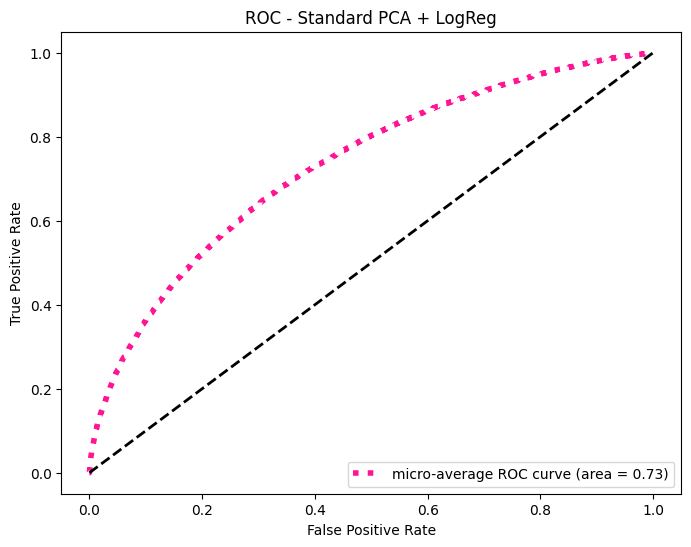

In [ ]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
import matplotlib.pyplot as plt

# 1. Determine K using the 'full' SVD solver with n_components=0.95
pca_full_pre_run = PCA(n_components=0.95, svd_solver='full', random_state=42)
pca_full_pre_run.fit(X_train_norm)
K_fixed = pca_full_pre_run.n_components_
print(f"Components (K) required for 95% energy (determined by 'full' SVD): {K_fixed}")
print("---")

def perform_pca_task(solver_type, K, X_train, X_test, y_train, y_test):
    print(f"\n--- Running {solver_type} PCA ---")

    # 1. PCA
    pca = PCA(n_components=K, svd_solver=solver_type, random_state=42)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    K_actual = pca.n_components_
    print(f"Components (K) used: {K_actual}")

    # 2. Logistic Regression
    # Using multinomial logistic regression
    clf = LogisticRegression(solver='lbfgs', max_iter=1000)
    clf.fit(X_train_pca, y_train)

    # Predict probabilities for ROC
    y_score = clf.predict_proba(X_test_pca)

    return pca, K_actual, y_score

# Run Standard PCA with the fixed K
pca_std, K_std, y_score_std = perform_pca_task('full', K_fixed, X_train_norm, X_test_norm, y_train, y_test)

# Run Randomized PCA with the fixed K
pca_rnd, K_rnd, y_score_rnd = perform_pca_task('randomized', K_fixed, X_train_norm, X_test_norm, y_train, y_test)

# --- Plotting ROC Curves ---
def plot_multiclass_roc(y_test, y_score, title):
    # Binarize the output for ROC calculation (One-vs-Rest)
    y_test_bin = label_binarize(y_test, classes=range(10))
    n_classes = 10

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    # Calculate ROC for each class
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Compute micro-average ROC curve
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

    plt.figure(figsize=(8, 6))
    plt.plot(fpr["micro"], tpr["micro"],
             label='micro-average ROC curve (area = {0:0.2f})'.format(roc_auc["micro"]),
             color='deeppink', linestyle=':', linewidth=4)

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(title)
    plt.legend(loc="lower right")
    plt.show()

plot_multiclass_roc(y_test, y_score_std, "ROC - Standard PCA + LogReg")

# Task 2

In [ ]:
from tensorflow.keras import layers, models, constraints, backend as K

class DenseTied(layers.Layer):
    def __init__(self, units, tied_to, **kwargs):
        super(DenseTied, self).__init__(**kwargs)
        self.units = units
        self.tied_to = tied_to

    def build(self, input_shape):
        super(DenseTied, self).build(input_shape)

    def call(self, inputs):
        weights = K.transpose(self.tied_to.kernel)
        return K.dot(inputs, weights)

# --- Build the Autoencoder ---
input_dim = 1024 # 32x32
encoding_dim = K_std # Use K from Task 1

inputs = layers.Input(shape=(input_dim,))

# Encoder: Linear activation + Unit Norm constraint
encoder_layer = layers.Dense(
    encoding_dim,
    activation='linear',
    use_bias=False,
    kernel_constraint=constraints.UnitNorm(axis=0),
    name="encoder"
)
encoded = encoder_layer(inputs)

# Decoder: Tied weights (Transpose of encoder)
decoded = DenseTied(units=input_dim, tied_to=encoder_layer)(encoded)

autoencoder = models.Model(inputs, decoded)

# Compile
autoencoder.compile(optimizer='adam', loss='mean_squared_error')

# Train
history = autoencoder.fit(
    X_train_norm, X_train_norm,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(X_test_norm, X_test_norm),
    verbose=1
)

Epoch 1/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.3403 - val_loss: 0.1088
Epoch 2/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0965 - val_loss: 0.0760
Epoch 3/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0711 - val_loss: 0.0636
Epoch 4/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0610 - val_loss: 0.0579
Epoch 5/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0563 - val_loss: 0.0552
Epoch 6/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0540 - val_loss: 0.0540
Epoch 7/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0530 - val_loss: 0.0534
Epoch 8/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0526 - val_loss: 0.0531
Epoch 9/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0523 - val_loss: 0.0529
Epoch 10/10
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0522 - val_loss: 0.0528


# compare eigen vectors from task 1 with autoencoders

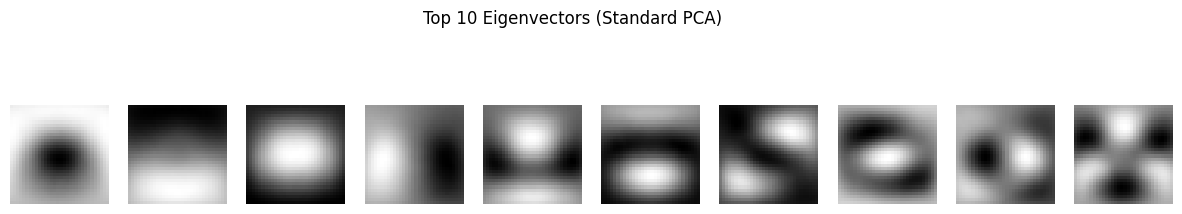

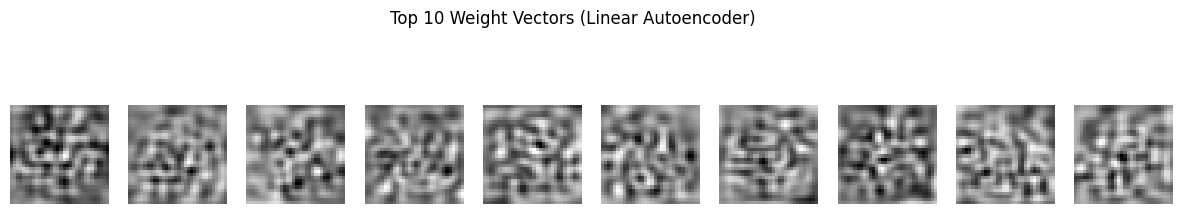

In [ ]:
# --- Visualization of Components ---

def plot_components(components, title, n_images=10):
    plt.figure(figsize=(15, 3))
    for i in range(n_images):
        ax = plt.subplot(1, n_images, i + 1)
        img = components[i].reshape(32, 32)
        plt.imshow(img, cmap='gray')
        plt.axis('off')
    plt.suptitle(title)
    plt.show()

# 1. Extract PCA Eigenvectors (Eigenfaces)
# PCA components_ shape is (n_components, n_features)
pca_components = pca_std.components_

# 2. Extract Autoencoder Weights
# AE Weights shape is (n_features, n_hidden). We need to transpose to match PCA shape.
ae_weights = encoder_layer.get_weights()[0].T

# Plot
plot_components(pca_components, "Top 10 Eigenvectors (Standard PCA)")
plot_components(ae_weights, "Top 10 Weight Vectors (Linear Autoencoder)")

Observation:
There is a visual difference between the two rows:

Row 1 (PCA): The images are smooth, structured, and geometric. They resemble gradients, blobs, and wave like patterns.

Row 2 (Autoencoder): The images appear "noisy," granular, or like "TV static," lacking distinct global shapes.

Analysis & Reasoning

1. PCA: Ordered Variance and Orthogonality

The images in the top row are Eigenfaces. PCA works sequentially to maximize variance.The first image (leftmost) captures the most dominant feature (likely the background illumination or the average circular shape of objects centered in CIFAR images).The subsequent images capture the next most important directions of variance, orthogonal to the previous ones.Because PCA concentrates the "energy" (information) into the earliest components, these vectors represent low frequency structures (smooth changes in lighting and shape), resulting in the blurry, smooth appearance.

2. Linear Autoencoder: Subspace Rotation (The "Why" for the Noise)We might expect the Autoencoder weights to look exactly like the PCA eigenvectors because a Linear Autoencoder with tied weights optimizes a similar objective to PCA (minimizing reconstruction error). However, they look noisy because there is no ordering constraint. Unlike PCA, the Autoencoder does not force the first node to be more important than the second. It optimizes all K nodes simultaneously.

Rotational Invariance: While the Autoencoder learns the same subspace as PCA (it covers the same mathematical ground), it finds a different basis to describe that space.

Distributed Representation: The Autoencoder "mixes" the PCA components together. Instead of having one lighting vector and one edge vector, the Autoencoder spreads this information across all the weight vectors. This mixing results in the noisy or high frequency appearance, as every weight vector is doing a little bit of work to reconstruct the image details.

Conclusion:

While both the PCA eigenvectors and the Linear Autoencoder weights span the same principal subspace, their visual representations differ significantly. PCA enforces an orthogonality and variance maximization constraint, resulting in smooth, and interpretable eigen-images.In contrast, the Linear Autoencoder lacks the constraint to align its weights along the axes of maximum variance. Consequently, it learns an arbitrary rotation of the PCA basis, distributing the image features (variance) continuously across all nodes, leading to weight vectors that appear visually mixed or granular."

# Task 3

In [ ]:
K = 64  # <<< IMPORTANT: set to the SAME K used in earlier tasks
batch_size = 256
epochs = 50
random_state = 42

np.random.seed(random_state)
tf.random.set_seed(random_state)

In [ ]:
input_shape = X_train.shape[1:]         # (32, 32, 1)
flat_dim = np.prod(input_shape).item()

# Single hidden layer dense autoencoder (baseline)
#    - One hidden layer with K nodes, sigmoid activation
#    - Output layer linear
def build_single_hidden_autoencoder(flat_dim, K):
    inp = layers.Input(shape=(flat_dim,), name="input_flat")
    hidden = layers.Dense(K, activation="sigmoid", name="hidden_sigmoid")(inp)
    out = layers.Dense(flat_dim, activation="linear", name="output_linear")(hidden)

    model = models.Model(inp, out, name="single_hidden_autoencoder")
    model.compile(optimizer=tf.keras.optimizers.Adam(),
                  loss="mse")  # MSE = reconstruction error
    return model

In [ ]:
# 5. Three-hidden-layer dense autoencoder
#    - Total K hidden nodes split across 3 layers
#      e.g., if K=64 -> [21, 21, 22]
#    - All hidden: sigmoid
#    - Output: linear
def build_three_hidden_autoencoder(flat_dim, K):
    # Distribute K nodes approximately equally across 3 layers
    base = K // 3
    sizes = [base, base, K - 2 * base]  # sum(sizes) = K

    inp = layers.Input(shape=(flat_dim,), name="input_flat")
    h1 = layers.Dense(sizes[0], activation="sigmoid", name="hidden1_sigmoid")(inp)
    h2 = layers.Dense(sizes[1], activation="sigmoid", name="hidden2_sigmoid")(h1)
    h3 = layers.Dense(sizes[2], activation="sigmoid", name="hidden3_sigmoid")(h2)
    out = layers.Dense(flat_dim, activation="linear", name="output_linear")(h3)

    model = models.Model(inp, out, name="three_hidden_autoencoder")
    model.compile(optimizer=tf.keras.optimizers.Adam(),
                  loss="mse")
    return model

In [ ]:
# 6. Deep convolutional autoencoder
#    - Latent space dimension ≈ K
#    - Conv encoder, Dense(K) bottleneck
#    - ConvTranspose decoder
#    - Output: linear
def build_conv_autoencoder(input_shape, K):
    inp = layers.Input(shape=input_shape, name="input_img", dtype=tf.float32)

    # ----- Encoder -----
    # 32x32x1 -> 16x16x32
    x = layers.Conv2D(32, (3, 3), strides=2, padding="same",
                      activation="relu", name="enc_conv1")(inp)
    # 16x16x32 -> 8x8x64
    x = layers.Conv2D(64, (3, 3), strides=2, padding="same",
                      activation="relu", name="enc_conv2")(x)

    # Flatten and bottleneck
    x_flat = layers.Flatten(name="flatten")(x)
    latent = layers.Dense(K, activation="relu", name="latent")(x_flat)

    # ----- Decoder -----
    # Map back up to 8x8x64
    x_dec = layers.Dense(8 * 8 * 64, activation="relu", name="dec_dense")(latent)
    x_dec = layers.Reshape((8, 8, 64), name="reshape_dec")(x_dec)

    # 8x8x64 -> 16x16x64
    x_dec = layers.Conv2DTranspose(64, (3, 3), strides=2, padding="same",
                                   activation="relu", name="dec_deconv1")(x_dec)
    # 16x16x64 -> 32x32x32
    x_dec = layers.Conv2DTranspose(32, (3, 3), strides=2, padding="same",
                                   activation="relu", name="dec_deconv2")(x_dec)

    # Final reconstruction: 32x32x1
    # Linear activation as requested for decoder final layer
    out = layers.Conv2D(1, (3, 3), padding="same",
                        activation="linear", name="output_linear")(x_dec)

    model = models.Model(inp, out, name="conv_autoencoder")
    model.compile(optimizer=tf.keras.optimizers.Adam(),
                  loss="mse")  # reconstruction error
    return model

In [ ]:
# 7. Prepare data for dense models (flattened)
x_train_flat = X_train_norm.reshape((X_train_norm.shape[0], flat_dim))
x_test_flat = X_test_norm.reshape((X_test_norm.shape[0], flat_dim))

In [ ]:
# 8. Build models
single_ae = build_single_hidden_autoencoder(flat_dim, K)
three_ae = build_three_hidden_autoencoder(flat_dim, K)
# The input_shape for the convolutional autoencoder should be (height, width, channels),
# which is (32, 32, 1) for grayscale CIFAR10 images.
# The original 'input_shape' variable holds (1024,), which is for flattened data.
conv_ae = build_conv_autoencoder((32, 32, 1), K)

single_ae.summary()
three_ae.summary()
conv_ae.summary()

Model: "single_hidden_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_flat (InputLayer)         │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_sigmoid (Dense)          │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_linear (Dense)           │ (None, 1024)           │        66,560 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 132,160 (516.25 KB)

 Trainable params: 132,160 (516.25 KB)

 Non-trainable params: 0 (0.00 B)

Model: "three_hidden_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_flat (InputLayer)         │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden1_sigmoid (Dense)         │ (None, 21)             │        21,525 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden2_sigmoid (Dense)         │ (None, 21)             │           462 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden3_sigmoid (Dense)         │ (None, 22)             │           484 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_linear (Dense)           │ (None, 1024)           │        23,552 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,023 (179.78 KB)

 Trainable params: 46,023 (179.78 KB)

 Non-trainable params: 0 (0.00 B)

Model: "conv_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_img (InputLayer)          │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv1 (Conv2D)              │ (None, 16, 16, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv2 (Conv2D)              │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_dense (Dense)               │ (None, 4096)           │       266,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_dec (Reshape)           │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_deconv1 (Conv2DTranspose)   │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_deconv2 (Conv2DTranspose)   │ (None, 32, 32, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_linear (Conv2D)          │ (None, 32, 32, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 602,945 (2.30 MB)

 Trainable params: 602,945 (2.30 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 9. Train models (with early stopping)
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

print("\nTraining single-hidden-layer dense autoencoder...")
history_single = single_ae.fit(
    x_train_flat, x_train_flat,
    validation_data=(x_test_flat, x_test_flat),
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[early_stop],
    verbose=1
)

print("\nTraining three-hidden-layer dense autoencoder...")
history_three = three_ae.fit(
    x_train_flat, x_train_flat,
    validation_data=(x_test_flat, x_test_flat),
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[early_stop],
    verbose=1
)

# Reshape data for convolutional autoencoder, using normalized data and casting to float32
X_train_conv = X_train_norm.reshape(-1, 32, 32, 1).astype(np.float32)
X_test_conv = X_test_norm.reshape(-1, 32, 32, 1).astype(np.float32)

print("\nTraining convolutional autoencoder...")
history_conv = conv_ae.fit(
    X_train_conv, X_train_conv,
    validation_data=(X_test_conv, X_test_conv),
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[early_stop],
    verbose=1
)


Training single-hidden-layer dense autoencoder...
Epoch 1/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.7115 - val_loss: 0.4011
Epoch 2/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3671 - val_loss: 0.3079
Epoch 3/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2907 - val_loss: 0.2638
Epoch 4/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2510 - val_loss: 0.2367
Epoch 5/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2253 - val_loss: 0.2194
Epoch 6/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2073 - val_loss: 0.2031
Epoch 7/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1936 - val_loss: 0.1907
Epoch 8/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1825 - val_loss: 0.1804
Epoch 9/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1737 - val_loss: 0.1728
Epoch 10/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1666 - val_loss: 0.1665
Epoch 11/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.1610 - val_loss: 0.1612


In [ ]:
# 10. Compute reconstruction error (MSE) on test set
mse_single = single_ae.evaluate(x_test_flat, x_test_flat, verbose=0)
mse_three = three_ae.evaluate(x_test_flat, x_test_flat, verbose=0)
mse_conv = conv_ae.evaluate(X_test_conv, X_test_conv, verbose=0)

print("\n================ Reconstruction Error (MSE) ================")
print(f"Single hidden layer (K nodes, sigmoid + linear output):   {mse_single:.6f}")
print(f"Three hidden layers (total K nodes, sigmoid + linear):    {mse_three:.6f}")
print(f"Deep convolutional autoencoder (latent dim \u2248 K):          {mse_conv:.6f}")
print("============================================================")


================ Reconstruction Error (MSE) ================
Single hidden layer (K nodes, sigmoid + linear output):   0.128155
Three hidden layers (total K nodes, sigmoid + linear):    0.374188
Deep convolutional autoencoder (latent dim ≈ K):          0.139345


# Task 4

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, losses
from tensorflow.keras.models import Model
from tensorflow.keras.models import Sequential #for MLP classifer
from tensorflow.keras.layers import Dense, Dropout
from tensorflow import keras # Import keras for regularizers
from keras.datasets import mnist
from keras.layers import Input, Dense, Conv2D, MaxPooling2D, UpSampling2D
from keras.models import Model
from keras import backend as K

In [ ]:
#Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
#explore the dataset
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [ ]:
x_train[2]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,  67, 232,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  62,  81,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0, 120, 180,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 126, 163,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   2, 153, 210,  40,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 220, 163,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,  27, 254, 162,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 222, 163,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0, 183, 254, 125,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,  46, 245, 163,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0, 198, 254,  56,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0, 120, 254, 163,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,  23, 231, 254,  29,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0, 159, 254, 120,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0, 163, 254, 216,  16,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0, 159, 254,  67,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  14,  86, 178, 248, 254,  91,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0, 159, 254,  85,   0,   0,   0,  47,  49, 116, 144,
        150, 241, 243, 234, 179, 241, 252,  40,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0, 150, 253, 237, 207, 207, 207, 253, 254, 250, 240,
        198, 143,  91,  28,   5, 233, 250,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 119, 177, 177, 177, 177, 177,  98,  56,   0,
          0,   0,   0,   0, 102, 254, 220,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 169, 254, 137,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 169, 254,  57,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 169, 254,  57,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 169, 255,  94,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 169, 254,  96,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 169, 254, 153,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 169, 255, 153,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   

### Train a deep convolutional autoencoder

In [ ]:
#reshape data to include channel dimension

x_train_reshape = x_train.reshape((len(x_train), 28, 28, 1))
x_test_reshape = x_test.reshape((len(x_test), 28, 28, 1))
print(f"Shape of x_train after reshaping: {x_train_reshape.shape}")
print(f"Shape of x_test after reshaping: {x_test_reshape.shape}")


Shape of x_train after reshaping: (60000, 28, 28, 1)
Shape of x_test after reshaping: (10000, 28, 28, 1)


In [ ]:
#define ENCODER

# Define input_img
input_img = Input(shape=(28, 28, 1))

conv1 = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
pool1 = MaxPooling2D((2, 2), padding='same')(conv1)
conv2 = Conv2D(32, (3, 3), activation='relu', padding='same')(pool1)
pool2 = MaxPooling2D((2, 2), padding='same')(conv2)
encoded = Conv2D(16, (3, 3), activation='relu', padding='same')(pool2)

In [ ]:
#define DECODER

conv3 = Conv2D(32, (3, 3), activation='relu', padding='same')(encoded)
up1 = UpSampling2D((2, 2))(conv3)
conv4 = Conv2D(32, (3, 3), activation='relu', padding='same')(up1)
up2 = UpSampling2D((2, 2))(conv4)
decoded = Conv2D(1, (3, 3), activation='sigmoid', padding='same')(up2)

In [ ]:
#build auto-encoder model
autoencoder = Model(input_img, decoded)

#Compile the autoencoder model with Adam optimizer and loss function
autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'], run_eagerly=True)


In [ ]:
# Normalize image data to [0, 1] range and convert to float32
x_train_normalized = x_train_reshape.astype('float32') / 255.
x_test_normalized = x_test_reshape.astype('float32') / 255.

print(f"Shape of normalized x_train: {x_train_normalized.shape}, Dtype: {x_train_normalized.dtype}")
print(f"Shape of normalized x_test: {x_test_normalized.shape}, Dtype: {x_test_normalized.dtype}")

Shape of normalized x_train: (60000, 28, 28, 1), Dtype: float32
Shape of normalized x_test: (10000, 28, 28, 1), Dtype: float32


In [ ]:
# Create TensorFlow Dataset objects for training and validation
train_dataset = tf.data.Dataset.from_tensor_slices((x_train_normalized, x_train_normalized)).batch(128)
test_dataset = tf.data.Dataset.from_tensor_slices((x_test_normalized, x_test_normalized)).batch(128)

autoencoder.fit(train_dataset,
                epochs=10,
                validation_data=test_dataset)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 71s 144ms/step - accuracy: 0.7979 - loss: 0.2197 - val_accuracy: 0.8139 - val_loss: 0.0791
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 67s 142ms/step - accuracy: 0.8144 - loss: 0.0775 - val_accuracy: 0.8142 - val_loss: 0.0738
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 61s 131ms/step - accuracy: 0.8147 - loss: 0.0729 - val_accuracy: 0.8144 - val_loss: 0.0715
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 56s 120ms/step - accuracy: 0.8148 - loss: 0.0707 - val_accuracy: 0.8144 - val_loss: 0.0703
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 57s 122ms/step - accuracy: 0.8149 - loss: 0.0695 - val_accuracy: 0.8144 - val_loss: 0.0692
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 56s 120ms/step - accuracy: 0.8149 - loss: 0.0687 - val_accuracy: 0.8144 - val_loss: 0.0686
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 57s 122ms/step - accuracy: 0.8149 - loss: 0.0681 - val_accuracy: 0.8144 - val_loss: 0.0677
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 58s 124ms/step - accuracy: 0.8149 - loss: 0

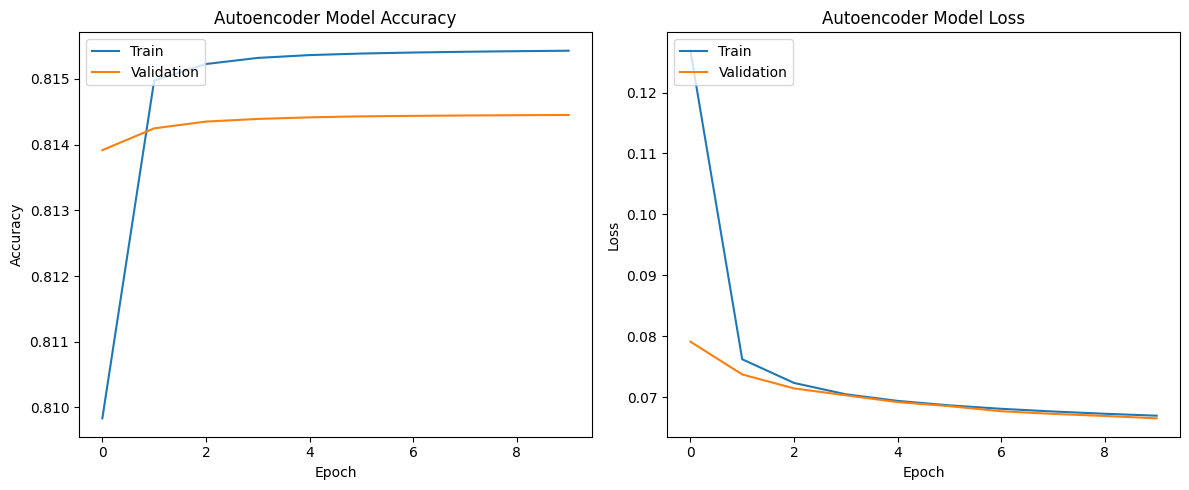

In [ ]:
#plot the accuracy, validation accuracy and validation loss
history = autoencoder.history

plt.figure(figsize=(12, 5))

# Plot training & validation accuracy values
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Autoencoder Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Autoencoder Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

### FEATURE EXTRACTION FROM CONVOLUTIONAL AUTO-ENCODER

In [ ]:
encoded_features_train = autoencoder.predict(x_train)
print(f"Shape of encoded training features: {encoded_features_train.shape}")

encoded_features_test = autoencoder.predict(x_test)
print(f"Shape of encoded features: {encoded_features_test.shape}")

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 68s 36ms/step
Shape of encoded training features: (60000, 28, 28, 1)
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step
Shape of encoded features: (10000, 28, 28, 1)


In [ ]:
flattened_features_train = encoded_features_train.reshape(encoded_features_train.shape[0], -1)
flattened_features_test = encoded_features_test.reshape(encoded_features_test.shape[0], -1)

print(f"Shape of flattened training features: {flattened_features_train.shape}")
print(f"Shape of flattened test features: {flattened_features_test.shape}")

Shape of flattened training features: (60000, 784)
Shape of flattened test features: (10000, 784)


Visualize the clusters

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 60000 samples in 0.026s...
[t-SNE] Computed neighbors for 60000 samples in 183.217s...
[t-SNE] Computed conditional probabilities for sample 1000 / 60000
[t-SNE] Computed conditional probabilities for sample 2000 / 60000
[t-SNE] Computed conditional probabilities for sample 3000 / 60000
[t-SNE] Computed conditional probabilities for sample 4000 / 60000
[t-SNE] Computed conditional probabilities for sample 5000 / 60000
[t-SNE] Computed conditional probabilities for sample 6000 / 60000
[t-SNE] Computed conditional probabilities for sample 7000 / 60000
[t-SNE] Computed conditional probabilities for sample 8000 / 60000
[t-SNE] Computed conditional probabilities for sample 9000 / 60000
[t-SNE] Computed conditional probabilities for sample 10000 / 60000
[t-SNE] Computed conditional probabilities for sample 11000 / 60000
[t-SNE] Computed conditional probabilities for sample 12000 / 60000
[t-SNE] Computed conditional probabilities for s

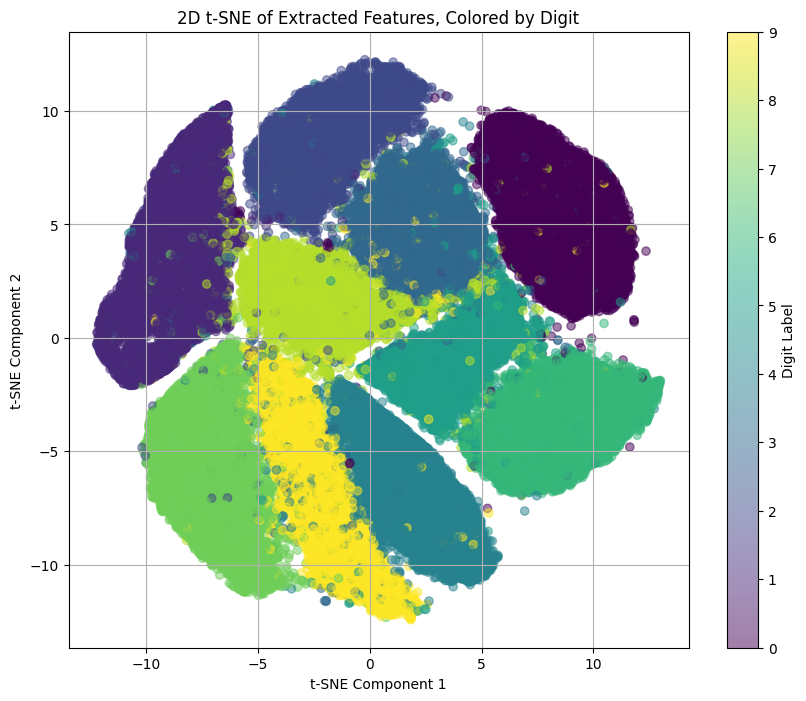

In [ ]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=42, verbose=1, perplexity=30, n_iter=300)
reduced_features_tsne = tsne.fit_transform(flattened_features_train)
plt.figure(figsize=(10, 8))
plt.scatter(reduced_features_tsne[:, 0], reduced_features_tsne[:, 1], c=y_train, cmap='viridis', alpha=0.5)
plt.colorbar(label='Digit Label')
plt.title('2D t-SNE of Extracted Features, Colored by Digit')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.grid(True)
plt.show()

In [ ]:
encoder = Model(input_img, encoded)

7-Segment LED Mapping


Reference:

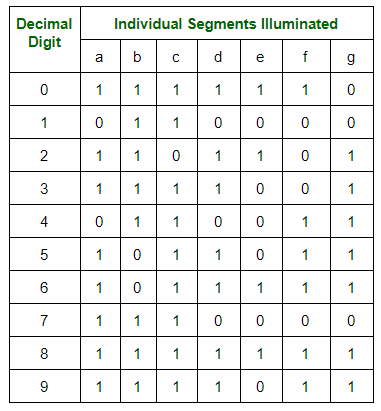

In [ ]:
# Define the 7-segment LED patterns for digits 0-9
# The order of segments can be A, B, C, D, E, F, G
#   A
# F   B
#   G
# E   C
#   D

seven_segment_map = {
    0: [1, 1, 1, 1, 1, 1, 0],  # All segments except G
    1: [0, 1, 1, 0, 0, 0, 0],  # B, C
    2: [1, 1, 0, 1, 1, 0, 1],  # A, B, D, E, G
    3: [1, 1, 1, 1, 0, 0, 1],  # A, B, C, D, G
    4: [0, 1, 1, 0, 0, 1, 1],  # B, C, F, G
    5: [1, 0, 1, 1, 0, 1, 1],  # A, C, D, F, G
    6: [1, 0, 1, 1, 1, 1, 1],  # A, C, D, E, F, G
    7: [1, 1, 1, 0, 0, 0, 0],  # A, B, C
    8: [1, 1, 1, 1, 1, 1, 1],  # All segments
    9: [1, 1, 1, 1, 0, 1, 1]   # A, B, C, D, F, G
}

print("7-segment LED mapping defined.")

7-segment LED mapping defined.


In [ ]:
#apply 7-segment to train and test to create target variables

y_train_7segment = np.array([seven_segment_map[digit] for digit in y_train])
y_test_7segment = np.array([seven_segment_map[digit] for digit in y_test])

print(f"Shape of 7-segment training labels: {y_train_7segment.shape}")
print(f"Shape of 7-segment test labels: {y_test_7segment.shape}")

Shape of 7-segment training labels: (60000, 7)
Shape of 7-segment test labels: (10000, 7)


### MLP Model for 7-LED Output
The input dimension will be the size of our flattened features, and the output layer will have 7 neurons with a sigmoid activation function

In [ ]:
# Input dimension for the MLP is the size of the flattened features
input_dim_mlp = flattened_features_train.shape[1]

mlp_model = Sequential([
    Dense(128, activation='relu', input_shape=(input_dim_mlp,), kernel_regularizer=keras.regularizers.l2(0.001)),
    Dropout(0.2),
    Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(0.001)),
    Dropout(0.2),
    Dense(7, activation='sigmoid') # 7 outputs for the 7 segments, sigmoid for binary classification per segment
])

mlp_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,191 (426.53 KB)

 Trainable params: 109,191 (426.53 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#binary_crossentropy is the loss function
#Adam optimizer is used

mlp_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.00001),
                  loss='binary_crossentropy',
                  metrics=['accuracy','precision','recall'])

In [ ]:
mlp_model.fit(flattened_features_train, y_train_7segment,
              epochs=30,
              batch_size=32,
              validation_data=(flattened_features_test, y_test_7segment))

Epoch 1/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - accuracy: 0.1218 - loss: 0.8670 - precision: 0.7612 - recall: 0.7998 - val_accuracy: 0.2509 - val_loss: 0.6429 - val_precision: 0.8185 - val_recall: 0.9615
Epoch 2/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.2481 - loss: 0.6378 - precision: 0.8344 - recall: 0.9273 - val_accuracy: 0.2733 - val_loss: 0.5000 - val_precision: 0.9022 - val_recall: 0.9602
Epoch 3/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.2681 - loss: 0.5209 - precision: 0.8869 - recall: 0.9363 - val_accuracy: 0.2992 - val_loss: 0.4199 - val_precision: 0.9265 - val_recall: 0.9640
Epoch 4/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.2811 - loss: 0.4506 - precision: 0.9111 - recall: 0.9441 - val_accuracy: 0.3045 - val_loss: 0.3727 - val_precision: 0.9400 - val_recall: 0.9656
Epoch 5/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.2924 - loss: 0.4067 - precision: 0.9246 - recall: 0.9499 - val_accuracy: 0.3235 - v

In [ ]:
#predict using MLP classifier
y_pred_mlp = mlp_model.predict(flattened_features_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


In [ ]:
#calculate accuracy on the test dataset of the MLP classifier
from sklearn.metrics import accuracy_score
accuracy_mlp = accuracy_score(y_test_7segment, y_pred_mlp.round())
print(f"Accuracy of MLP Classifier: {accuracy_mlp}")


Accuracy of MLP Classifier: 0.903


Visualize Predicted 7-Segment LED Displays

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


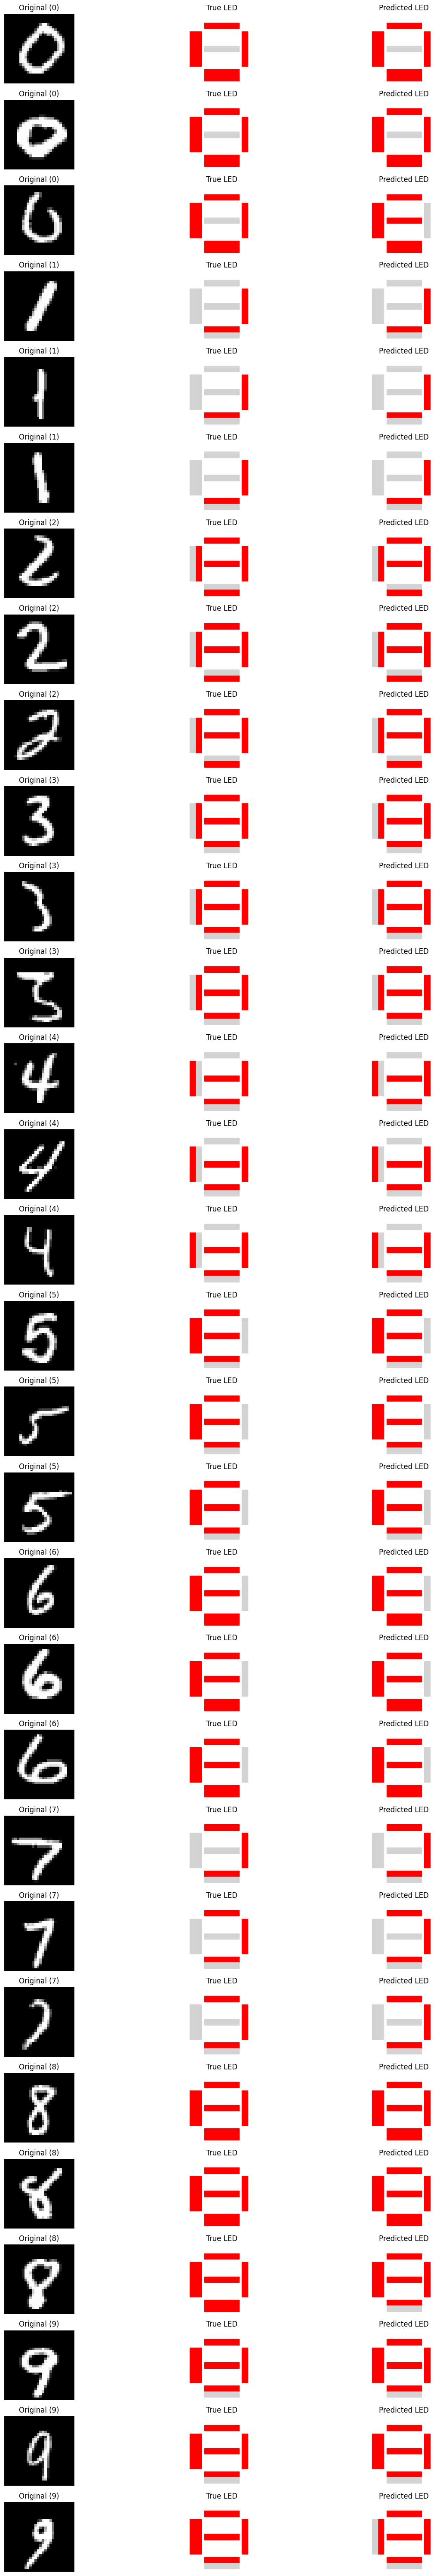

Visualization of predicted 7-segment LED displays complete.


In [ ]:
# Get MLP predictions for the test set
y_pred_mlp_prob = mlp_model.predict(flattened_features_test)
# Convert probabilities to binary (0 or 1) using a threshold of 0.5
y_pred_mlp_binary = (y_pred_mlp_prob > 0.5).astype(int)

# Function to draw a 7-segment display
def draw_7_segment(ax, segments, title=""):
    # Segment coordinates (relative to a 10x10 grid for drawing)
    #   A
    # F   B
    #   G
    # E   C
    #   D
    segment_coords = {
        0: [(2, 9), (8, 9)], # A
        1: [(9, 8), (9, 2)], # B
        2: [(8, 1), (2, 1)], # C
        3: [(1, 2), (1, 8)], # D
        4: [(2, 0), (8, 0)], # E
        5: [(0, 8), (0, 2)], # F
        6: [(2, 5), (8, 5)]  # G
    }

    ax.set_xlim(-1, 11)
    ax.set_ylim(-1, 11)
    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    ax.set_title(title)

    for i, (start, end) in segment_coords.items():
        color = 'red' if segments[i] == 1 else 'lightgray'
        # Adjust thickness for horizontal vs vertical
        if i in [0, 2, 4, 6]: # Horizontal segments
            ax.add_patch(patches.Rectangle((start[0], start[1] - 0.5), end[0] - start[0], 1, color=color))
        else: # Vertical segments
            ax.add_patch(patches.Rectangle((start[0] - 0.5, start[1]), 1, end[1] - start[1], color=color))

# Display predictions for a few examples of each digit
num_examples_per_digit = 3

plt.figure(figsize=(15, 2 * 10 * num_examples_per_digit))

for digit in range(10):
    # Get indices for this digit from the test set
    digit_indices = np.where(y_test == digit)[0]
    np.random.shuffle(digit_indices) # Shuffle to get random examples

    for i in range(min(num_examples_per_digit, len(digit_indices))):
        idx = digit_indices[i]

        # Original MNIST Image
        ax1 = plt.subplot(10 * num_examples_per_digit, 3, (digit * num_examples_per_digit + i) * 3 + 1)
        ax1.imshow(x_test[idx].reshape(28, 28), cmap='gray')
        ax1.set_title(f"Original ({digit})")
        ax1.axis('off')

        # True 7-segment LED
        ax2 = plt.subplot(10 * num_examples_per_digit, 3, (digit * num_examples_per_digit + i) * 3 + 2)
        draw_7_segment(ax2, y_test_7segment[idx], "True LED")

        # Predicted 7-segment LED
        ax3 = plt.subplot(10 * num_examples_per_digit, 3, (digit * num_examples_per_digit + i) * 3 + 3)
        draw_7_segment(ax3, y_pred_mlp_binary[idx], "Predicted LED")

plt.tight_layout()
plt.show()

print("Visualization of predicted 7-segment LED displays complete.")
